# Heart Disease Prediction System

**Deployment Link:** https://app-project-nvnhspb9utesbqjurxoejv.streamlit.app/

**Abdullah Hassan | FA24-BSE-007**

**Dataset:** [UCI Heart Disease Dataset](https://archive.ics.uci.edu/dataset/45/heart+disease) (Processed Cleveland)

**Selected Features (4 input attributes):** age, sex, cp (chest pain type), thalach (max heart rate)

## Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## Step 2: Load Data

In [2]:
df = pd.read_csv('heart.csv')
print(f'Dataset Shape: {df.shape}')
df.head()

Dataset Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Step 3: Data Understanding

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [4]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [5]:
# Check for missing values
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

In [6]:
# Target variable distribution (num: 0 = no disease, 1-4 = disease)
df['num'].value_counts()

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

## Step 4: Data Preprocessing

- Binarize the target: 0 = No Heart Disease, 1 = Heart Disease (values 1-4)
- Select only 4 input features
- Handle any missing values

In [7]:
# Binarize target
df['target'] = (df['num'] > 0).astype(int)
print('Target Distribution:')
print(df['target'].value_counts())
print()
print(f'0 = No Disease: {(df["target"] == 0).sum()}')
print(f'1 = Disease: {(df["target"] == 1).sum()}')

Target Distribution:
target
0    164
1    139
Name: count, dtype: int64

0 = No Disease: 164
1 = Disease: 139


In [8]:
# Select 4 input features
features = ['age', 'sex', 'cp', 'thalach']
X = df[features].copy()
y = df['target'].copy()
print(f'Features shape: {X.shape}')
X.head()

Features shape: (303, 4)


,age,sex,cp,thalach
0,63.0,1.0,1.0,150.0
1,67.0,1.0,4.0,108.0
2,67.0,1.0,4.0,129.0
3,37.0,1.0,3.0,187.0
4,41.0,0.0,2.0,172.0


## Step 5: Exploratory Data Analysis (EDA)

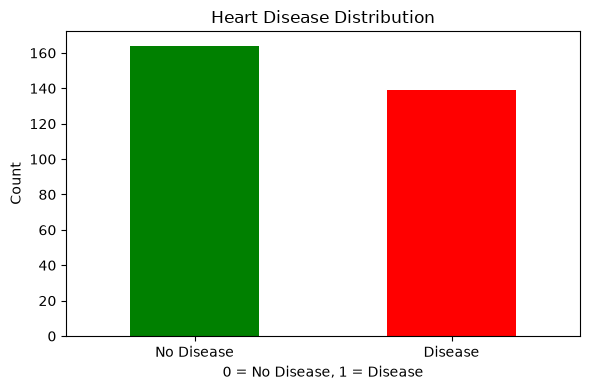

In [9]:
# Target distribution
fig, ax = plt.subplots(figsize=(6, 4))
df['target'].value_counts().plot(kind='bar', color=['green', 'red'], ax=ax)
ax.set_title('Heart Disease Distribution')
ax.set_xlabel('0 = No Disease, 1 = Disease')
ax.set_ylabel('Count')
ax.set_xticklabels(['No Disease', 'Disease'], rotation=0)
plt.tight_layout()
plt.show()

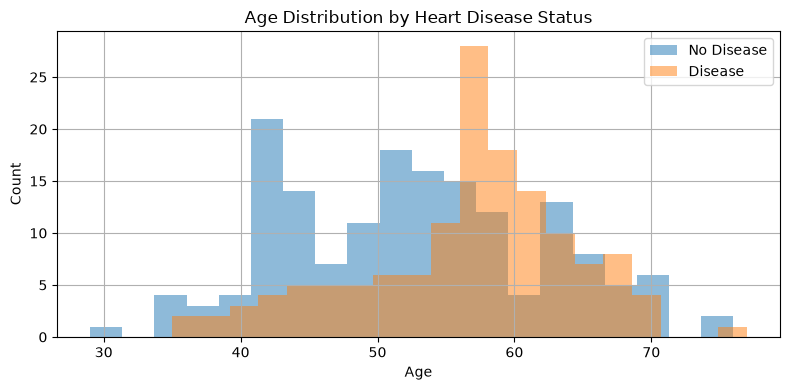

In [10]:
# Age distribution by target
fig, ax = plt.subplots(figsize=(8, 4))
df[df['target'] == 0]['age'].hist(alpha=0.5, label='No Disease', bins=20, ax=ax)
df[df['target'] == 1]['age'].hist(alpha=0.5, label='Disease', bins=20, ax=ax)
ax.set_title('Age Distribution by Heart Disease Status')
ax.set_xlabel('Age')
ax.set_ylabel('Count')
ax.legend()
plt.tight_layout()
plt.show()

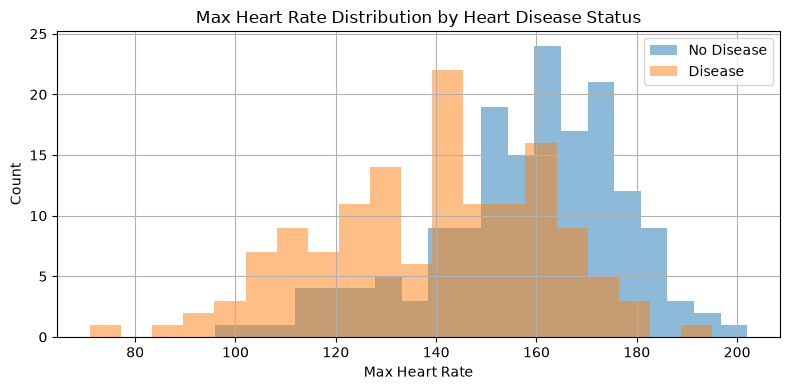

In [11]:
# Max heart rate by target
fig, ax = plt.subplots(figsize=(8, 4))
df[df['target'] == 0]['thalach'].hist(alpha=0.5, label='No Disease', bins=20, ax=ax)
df[df['target'] == 1]['thalach'].hist(alpha=0.5, label='Disease', bins=20, ax=ax)
ax.set_title('Max Heart Rate Distribution by Heart Disease Status')
ax.set_xlabel('Max Heart Rate')
ax.set_ylabel('Count')
ax.legend()
plt.tight_layout()
plt.show()

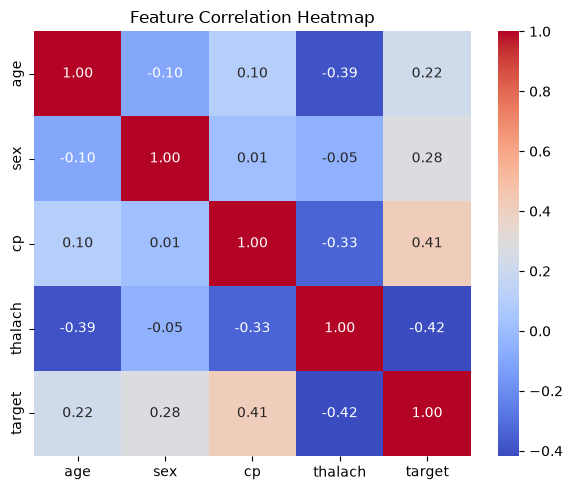

In [12]:
# Correlation heatmap of selected features
fig, ax = plt.subplots(figsize=(6, 5))
corr_data = df[features + ['target']].corr()
sns.heatmap(corr_data, annot=True, cmap='coolwarm', fmt='.2f', ax=ax)
ax.set_title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

## Step 6: Label Encoding

- **sex**: 0 = Female, 1 = Male
- **cp**: Chest pain type 1-4 (encode using LabelEncoder)

In [13]:
# Label Encoding
le_sex = LabelEncoder()
le_cp = LabelEncoder()

X['sex'] = le_sex.fit_transform(X['sex'].astype(int))
X['cp'] = le_cp.fit_transform(X['cp'].astype(int))

print('Label Encoder - Sex classes:', le_sex.classes_)
print('Label Encoder - CP classes:', le_cp.classes_)
print()
X.head()

Label Encoder - Sex classes: [0 1]
Label Encoder - CP classes: [1 2 3 4]



,age,sex,cp,thalach
0,63.0,1,0,150.0
1,67.0,1,3,108.0
2,67.0,1,3,129.0
3,37.0,1,2,187.0
4,41.0,0,1,172.0


## Step 7: Feature Scaling

Standardize all features so age and thalach (large ranges) don't dominate sex and cp (small ranges).

In [14]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=features)
X_scaled.head()

,age,sex,cp,thalach
0,0.948726,0.686202,-2.251775,0.017197
1,1.392002,0.686202,0.877985,-1.821905
2,1.392002,0.686202,0.877985,-0.902354
3,-1.932564,0.686202,-0.165268,1.637359
4,-1.489288,-1.457296,-1.208521,0.980537


## Step 8: Train-Test Split (80/20)

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=0)
print(f'Training set: {X_train.shape[0]} samples')
print(f'Test set: {X_test.shape[0]} samples')

Training set: 242 samples
Test set: 61 samples


## Step 9: Model Training (Logistic Regression)

In [16]:
model = LogisticRegression(random_state=0, max_iter=1000)
model.fit(X_train, y_train)
print('Model trained successfully!')

Model trained successfully!


## Step 10: Model Evaluation

In [17]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')
print()
print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred))
print()
print('Classification Report:')
print(classification_report(y_test, y_pred))

Accuracy: 0.77

Confusion Matrix:
[[28  7]
 [ 7 19]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.80      0.80        35
           1       0.73      0.73      0.73        26

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.77      0.77      0.77        61



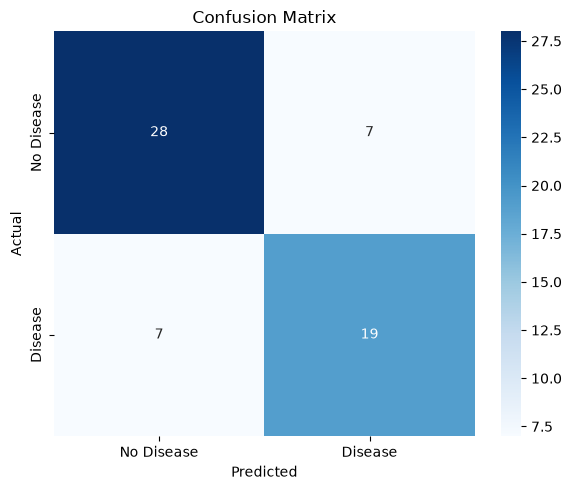

In [18]:
# Confusion matrix heatmap
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['No Disease', 'Disease'],
            yticklabels=['No Disease', 'Disease'])
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('Confusion Matrix')
plt.tight_layout()
plt.show()

## Step 11: Save Trained Model

In [19]:
# Save model and scaler together
model_data = {
    'model': model,
    'scaler': scaler
}

with open('heart_disease_model.pkl', 'wb') as f:
    pickle.dump(model_data, f)

print('Model saved as heart_disease_model.pkl')

Model saved as heart_disease_model.pkl


## Step 12: Test Prediction

In [20]:
# Load and test the saved model
with open('heart_disease_model.pkl', 'rb') as f:
    loaded_data = pickle.load(f)

loaded_model = loaded_data['model']
loaded_scaler = loaded_data['scaler']

# Test: 55 year old male, asymptomatic chest pain, heart rate 120
sample = pd.DataFrame({
    'age': [55],
    'sex': [1],
    'cp': [3],
    'thalach': [120]
})

sample_scaled = loaded_scaler.transform(sample)
prediction = loaded_model.predict(sample_scaled)[0]

if prediction == 1:
    print('Prediction: Heart Disease Detected')
else:
    print('Prediction: No Heart Disease')

Prediction: Heart Disease Detected


C:\Users\My PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


## Step 13: Deployment

The model is deployed using **Streamlit** and hosted on **Streamlit Community Cloud**.

**Live Link:** https://app-project-nvnhspb9utesbqjurxoejv.streamlit.app/

### Deployment files:
- `app.py` - Streamlit application
- `heart_disease_model.pkl` - Trained model + scaler
- `requirements.txt` - Python dependencies